# Home Credit default risk: report notebook

This notebook follows the README with the tables and charts behind each statement. Small tables are computed here
from the processed data; results of long runs are read from `analysis_output/` (each file's script is listed in
`OUTPUTS.md`). Only aggregated numbers are shown: the competition data may not be redistributed.

The chosen model is **LightGBM v2** (`lgbm_v2_combo_lr02_x3`): 186 columns, no gender or family status, learning
rate 0.02, average of 3 fits.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # the repository root, so the project's own modules import
import pandas as pd
import io

import matplotlib.pyplot as plt
from IPython.display import Image, display

from homecredit import figures
from homecredit.data import read_raw
from homecredit.paths import Paths

P = Paths()
R = P.results
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def show(fig):
    """Show a chart from homecredit/figures.py as a PNG image (the same rendering as the README files)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", facecolor=fig.get_facecolor())
    plt.close(fig)
    return Image(buf.getvalue())

## 1. The data
Computed live from the Parquet copies of the Kaggle files.

In [2]:
tr = read_raw(P, "application_train", ["TARGET", "NAME_CONTRACT_TYPE"])
te = read_raw(P, "application_test", ["NAME_CONTRACT_TYPE"])
print(f"train applicants {len(tr):,}; test applicants {len(te):,}; "
      f"payment difficulties in train {100 * tr.TARGET.mean():.2f}%")
mix = pd.DataFrame({"train %": tr.NAME_CONTRACT_TYPE.value_counts(normalize=True) * 100,
                    "test %": te.NAME_CONTRACT_TYPE.value_counts(normalize=True) * 100}).round(2)
display(mix)

train applicants 307,511; test applicants 48,744; payment difficulties in train 8.07%


,train %,test %
NAME_CONTRACT_TYPE,,
Cash loans,90.48,99.1
Revolving loans,9.52,0.9


## 2. First findings: the test set is a different mix
Single columns that differ between train and test (EDA step 5), the loan-term detail, and how well a model can
tell test rows from train rows (adversarial validation).

In [3]:
display(pd.read_csv(R / "eda" / "drift_details.csv"))
display(pd.read_csv(R / "eda" / "feature_drift_loan_terms.csv"))
adv = pd.read_csv(R / "eda" / "feature_adversarial_summary.csv")
display(adv[adv.model.isna()])

,column,value,test,train
0,AMT_REQ_CREDIT_BUREAU_QRT,(missing),12.41,13.50
1,AMT_REQ_CREDIT_BUREAU_QRT,0.0,48.33,70.05
2,AMT_REQ_CREDIT_BUREAU_QRT,1.0,31.95,11.01
3,AMT_REQ_CREDIT_BUREAU_QRT,2.0,6.15,4.69
4,AMT_REQ_CREDIT_BUREAU_QRT,>2,1.16,0.75
5,NAME_CONTRACT_TYPE,Cash loans,99.10,90.48
6,NAME_CONTRACT_TYPE,Revolving loans,0.90,9.52


,feature,statistic,train_cash,test_cash
0,annuity_to_credit,quantile 0.05,0.0287,0.0324
1,annuity_to_credit,quantile 0.1,0.0293,0.0378
2,annuity_to_credit,quantile 0.25,0.0359,0.0485
3,annuity_to_credit,quantile 0.5,0.0484,0.0616
4,annuity_to_credit,quantile 0.75,0.0668,0.0795
5,annuity_to_credit,quantile 0.9,0.0978,0.1053
6,annuity_to_credit,quantile 0.95,0.1055,0.1093
7,credit_to_goods,quantile 0.05,1.0000,1.0000
8,credit_to_goods,quantile 0.1,1.0000,1.0000
9,credit_to_goods,quantile 0.25,1.0000,1.0000


,measure,model,scope,value
0,"adversarial AUC, mean of 5 folds",NaN,NaN,0.95688
1,"adversarial AUC, sd of 5 folds",NaN,NaN,0.00067
2,effective sample size of weights (train rows),NaN,NaN,9506.44496
3,"effective sample size, % of train",NaN,NaN,3.09142
4,largest weight (mean = 1),NaN,NaN,1556.58858


## 3. Validation and noise
5 stratified folds x 5 seeds. `fold_sd` is how much one fold's AUC moves; the paired rule (gain over twice its
bootstrap SE and at least 18 of 25 wins) is applied in `experiments/compare.py`.

In [4]:
display(pd.read_csv(R / "validation" / "noise_summary.csv"))

,model,scope,mean_auc,fold_sd,seed_sd,seed_mean_min,seed_mean_max
0,logreg,all,0.73730,0.00236,0.00004,0.73724,0.73733
1,logreg,cash,0.73588,0.00236,0.00004,0.73581,0.73592
2,rule,all,0.71647,0.00279,0.00001,0.71646,0.71648
3,rule,cash,0.71635,0.00263,0.00001,0.71634,0.71635


## 4. Results: every model

,model,family,features,sensitive_columns_used,folds,cv_auc_all,cv_auc_cash,note
0,rule,"rule, no training",1 - mean of EXT_SOURCE_1/2/3,no,25,0.71647,0.71635,baseline
1,logreg_baseline,logistic regression,15 hand-picked application columns,gender,25,0.73730,0.73588,baseline
2,scorecard_app,WOE scorecard,application form only,gender + family,25,0.74327,0.74159,NaN
3,scorecard_full_no_gender,WOE scorecard,v1,no,25,0.75528,0.75420,explainable comparison
4,scorecard_full,WOE scorecard,v1: form + 22 history summaries,gender,25,0.75647,0.75544,NaN
5,mlp_v2_combo_s0,neural net (MLP),v2,no,5,0.76811,0.76739,seed 0 only (exploratory)
6,lgbm_v1_no_sensitive,LightGBM,v1 without age too,no (no age),25,0.77588,0.77537,fairness test
7,lgbm_v1_no_gender_family,LightGBM,v1,no,25,0.77732,0.77697,fairness test; v2 reference
8,lgbm_v2_ext,LightGBM,v1 + external-score combinations,no,25,0.77754,0.77709,feature test (no gain)
9,lgbm_v1_no_gender,LightGBM,v1,family,25,0.77773,0.77726,fairness test


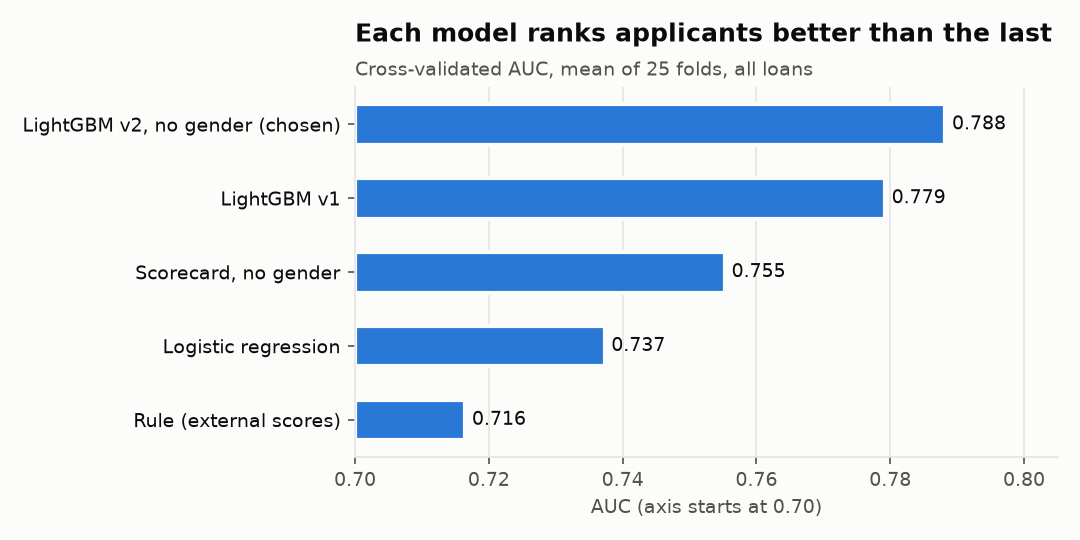

In [5]:
s = pd.read_csv(R / "model_summary.csv")
display(s[["model", "family", "features", "sensitive_columns_used", "folds", "cv_auc_all", "cv_auc_cash", "note"]])
show(figures.auc_by_model(P))

Each step of the main path, as paired comparisons on the same 25 folds (cash loans):

In [6]:
steps = [("logreg_baseline", "scorecard_app"), ("scorecard_app", "scorecard_full"),
         ("scorecard_full", "lgbm_v1"), ("lgbm_v1_no_gender_family", "lgbm_v2_combo"),
         ("lgbm_v2_combo", "lgbm_v2_combo_lr02"), ("lgbm_v2_combo_lr02", "lgbm_v2_combo_lr02_x3"),
         ("lgbm_v1", "lgbm_v2_combo_lr02_x3")]
rows = [pd.read_csv(R / "comparisons" / f"{a}_vs_{b}.csv").query("scope == 'cash'") for a, b in steps]
display(pd.concat(rows, ignore_index=True))

,a,b,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_25,verdict
0,logreg_baseline,scorecard_app,cash,0.73588,0.74159,0.00571,0.00063,25,B better (beats noise)
1,scorecard_app,scorecard_full,cash,0.74159,0.75544,0.01385,0.00060,25,B better (beats noise)
2,scorecard_full,lgbm_v1,cash,0.75544,0.77879,0.02335,0.00079,25,B better (beats noise)
3,lgbm_v1_no_gender_family,lgbm_v2_combo,cash,0.77697,0.78451,0.00754,0.00059,25,B better (beats noise)
4,lgbm_v2_combo,lgbm_v2_combo_lr02,cash,0.78451,0.78625,0.00174,0.00031,25,B better (beats noise)
5,lgbm_v2_combo_lr02,lgbm_v2_combo_lr02_x3,cash,0.78625,0.78771,0.00147,0.00017,25,B better (beats noise)
6,lgbm_v1,lgbm_v2_combo_lr02_x3,cash,0.77879,0.78771,0.00893,0.00056,25,B better (beats noise)


## 5. The independent check: Kaggle late submissions
Scores typed from the Kaggle submissions page (`analysis_output/kaggle/kaggle_scores.csv`). Nothing was chosen or
changed because of them.

,model,private_auc,public_auc,cv_auc_all,cv_auc_cash,private_minus_cv_cash,public_minus_private
0,lgbm_v2_combo_lr02_x3,0.78782,0.78971,0.78823,0.78771,0.00011,0.00189
1,lgbm_v2_combo_lr02,0.78679,0.78940,0.78678,0.78625,0.00054,0.00261
2,lgbm_v2_combo_with_gender,0.78794,0.78866,0.78662,0.78614,0.00180,0.00072
3,lgbm_v2_combo,0.78453,0.78803,0.78502,0.78451,0.00002,0.00350
4,lgbm_v2_stk,0.78380,0.78638,0.78134,0.78085,0.00295,0.00258
5,lgbm_v2_stk_nobb,0.78207,0.78394,0.78111,0.78063,0.00144,0.00187
6,lgbm_v2_term,0.78084,0.78486,0.78079,0.78023,0.00061,0.00402
7,lgbm_v2_win,0.77922,0.78502,0.78014,0.77959,-0.00037,0.00580
8,lgbm_v1,0.77994,0.78497,0.77921,0.77879,0.00115,0.00503
9,lgbm_v1_no_gender,0.77846,0.78540,0.77773,0.77726,0.00120,0.00694


,reference,change,cv_gain_cash,private_gain,public_gain,rough_se_private,private_gain_over_2se,same_sign_as_cv
0,lgbm_v1,lgbm_v1_no_gender,-0.00153,-0.00148,0.00043,0.00096,False,True
1,lgbm_v1,lgbm_v1_no_gender_family,-0.00182,-0.00222,-0.00147,0.00110,True,True
2,lgbm_v1_no_gender_family,lgbm_v2_win,0.00262,0.00150,0.00152,0.00128,False,True
3,lgbm_v1_no_gender_family,lgbm_v2_stk_nobb,0.00366,0.00435,0.00044,0.00123,True,True
4,lgbm_v1_no_gender_family,lgbm_v2_term,0.00326,0.00312,0.00136,0.00123,True,True
5,lgbm_v2_stk_nobb,lgbm_v2_stk,0.00022,0.00173,0.00244,0.00099,False,True
6,lgbm_v1_no_gender_family,lgbm_v2_combo,0.00754,0.00681,0.00453,0.00158,True,True
7,lgbm_v2_combo_with_gender,lgbm_v2_combo,-0.00163,-0.00341,-0.00063,0.00104,True,True
8,lgbm_v2_combo,lgbm_v2_combo_lr02,0.00174,0.00226,0.00137,0.00083,True,True
9,lgbm_v2_combo_lr02,lgbm_v2_combo_lr02_x3,0.00146,0.00103,0.00031,0.00045,True,True


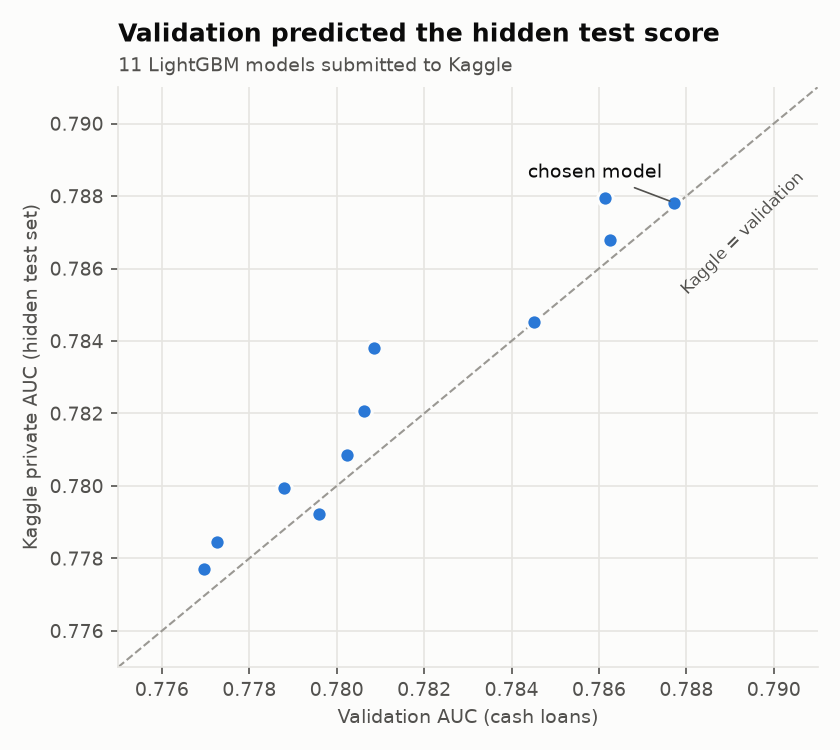

In [7]:
display(pd.read_csv(R / "kaggle" / "kaggle_vs_cv.csv"))
display(pd.read_csv(R / "kaggle" / "kaggle_steps_v2.csv"))
show(figures.cv_vs_kaggle(P))

## 6. Calibration
ECE = average gap between predicted and observed, in points. Measured inside each validation fold and compared with
the value a perfectly calibrated model would show (`floor_pts`); the pooled ECE in `summary_v2.csv` flatters the
cross-fitted isotonic correction.

,model,version,scope,ece_by_fold_pts,floor_pts
0,lgbm_v1,raw,all,0.4954,0.3344
1,lgbm_v1,raw,cash,0.5039,0.3694
2,lgbm_v1,platt,all,0.4752,0.3374
3,lgbm_v1,platt,cash,0.4832,0.3707
4,lgbm_v1,isotonic,all,0.3752,0.3368
5,lgbm_v1,isotonic,cash,0.3933,0.3669
6,lgbm_v2_combo_lr02_x3,raw,all,0.4831,0.3451
7,lgbm_v2_combo_lr02_x3,raw,cash,0.5032,0.3571
8,lgbm_v2_combo_lr02_x3,platt,all,0.4760,0.3467
9,lgbm_v2_combo_lr02_x3,platt,cash,0.4917,0.3590


,model,version,scope,auc,mean_pred_pct,observed_pct,slope,brier,log_loss
0,lgbm_v1,raw,all,0.779177,7.999097,8.072882,0.986096,0.066457,0.239679
1,lgbm_v1,raw,cash,0.778753,8.258736,8.345913,0.981752,0.068339,0.245200
2,lgbm_v1,platt,all,0.779156,8.072647,8.072882,0.999325,0.066449,0.239673
3,lgbm_v1,platt,cash,0.778733,8.331050,8.345913,0.994993,0.068331,0.245188
4,lgbm_v1,isotonic,all,0.778549,8.072922,8.072882,0.993536,0.066451,0.239716
5,lgbm_v1,isotonic,cash,0.778141,8.330935,8.345913,0.990991,0.068335,0.245264
6,lgbm_v2_combo_lr02_x3,raw,all,0.788210,7.975507,8.072882,1.010904,0.065877,0.236827
7,lgbm_v2_combo_lr02_x3,raw,cash,0.787692,8.235842,8.345913,1.006476,0.067740,0.242298
8,lgbm_v2_combo_lr02_x3,platt,all,0.788198,8.072598,8.072882,0.999982,0.065883,0.236820
9,lgbm_v2_combo_lr02_x3,platt,cash,0.787680,8.337897,8.345913,0.995753,0.067746,0.242294


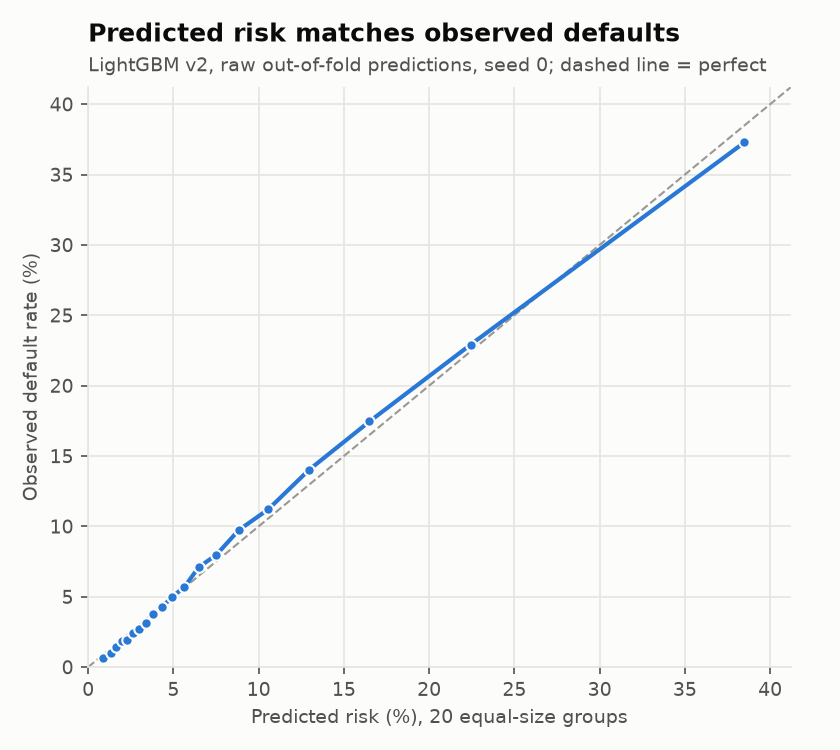

In [8]:
display(pd.read_csv(R / "calibration" / "ece_by_fold_v2.csv"))
c = pd.read_csv(R / "calibration" / "summary_v2.csv")
display(c[["model", "version", "scope", "auc", "mean_pred_pct", "observed_pct", "slope", "brier", "log_loss"]])
show(figures.calibration(P))

## 7. Reason codes
At the proposed cut-off (decline about 6%). Top-3 reason groups per declined applicant (SHAP for LightGBM; points
below the approved average for the scorecard), and the counterfactual test: replace one reason group with an
approved applicant's values and re-score. `top4` (the next reason) is a closer control than a random unused group.

,model,reason_group,pct_declines_top1,pct_declines_in_top3
0,lightgbm (SHAP),External credit scores,81.23,94.85
1,lightgbm (SHAP),Repayment of earlier Home Credit loans,6.45,37.91
2,lightgbm (SHAP),Loan size and terms vs income,4.84,46.94
3,lightgbm (SHAP),Credit card use,3.80,19.57
4,lightgbm (SHAP),Earlier Home Credit applications,1.32,31.22
5,lightgbm (SHAP),Loans still running at Home Credit,0.85,8.97
6,lightgbm (SHAP),Employment and income type,0.80,32.89
7,lightgbm (SHAP),Loans with other lenders,0.68,22.19


,rank,tested,mean_risk_drop_pts,flip_to_approve_pct,folds_where_top_beats_next
0,top1,17666.0,20.135427,82.795200,5.0
1,top2,17666.0,11.180699,56.894600,5.0
2,top3,17666.0,7.449235,40.787954,5.0
3,control,17666.0,0.564014,8.512397,NaN
4,top4,17666.0,5.031215,29.592437,5.0


,model,flag,pct_declines_top1,pct_declines_any_top3
0,lightgbm (SHAP),"sensitive (age, gender, family)",0.0,0.10
1,lightgbm (SHAP),"not a fair reason (application day/hour, conta...",0.0,0.56
2,scorecard (points below max),"sensitive (age, gender, family)",0.0,0.00
3,scorecard (points below max),"not a fair reason (application day/hour, conta...",0.0,0.00
4,scorecard (points below approved average),"sensitive (age, gender, family)",0.0,0.00
5,scorecard (points below approved average),"not a fair reason (application day/hour, conta...",0.0,0.08


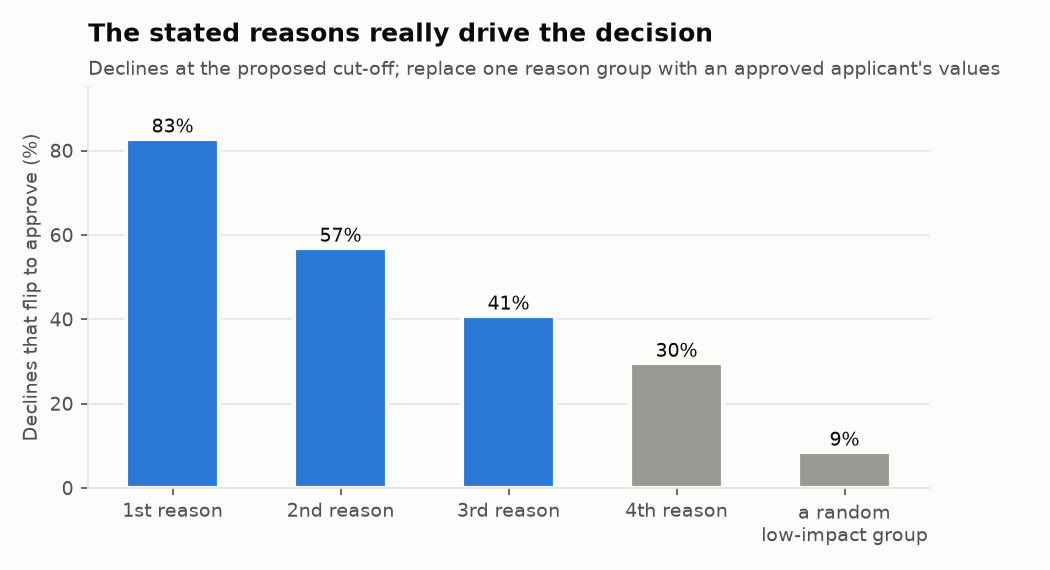

In [9]:
rs = pd.read_csv(R / "reasons_v2_cut06" / "top_reason_share.csv")
display(rs[rs.model == "lightgbm (SHAP)"].head(8))
display(pd.read_csv(R / "reasons_v2_cut06" / "counterfactual_summary.csv"))
display(pd.read_csv(R / "reasons_v2_cut06" / "sensitive_reasons.csv"))
show(figures.reason_counterfactual(P))

## 8. Error analysis (chosen model)
AUC inside each group and its share of the wrongly ordered pairs; a `missed_ratio` above 1 means the group's
defaulters cost more than their share.

In [10]:
seg = pd.read_csv(R / "errors_v2" / "segments.csv")
display(seg[seg.segment.isin(["age band", "income type"])][
    ["segment", "group", "applicants", "default_rate_pct", "auc_within", "missed_ratio", "false_alarm_ratio"]])
display(pd.read_csv(R / "errors_v2" / "candidate_signals.csv"))
display(pd.read_csv(R / "validation" / "duplicate_check.csv"))

,segment,group,applicants,default_rate_pct,auc_within,missed_ratio,false_alarm_ratio
2,income type,Commercial associate,71617,7.48,0.7848,1.07,0.95
3,income type,Other,55,18.18,0.8884,0.25,1.00
4,income type,Pensioner,55362,5.39,0.7583,1.52,0.68
5,income type,State servant,21703,5.75,0.7876,1.34,0.72
6,income type,Working,158774,9.59,0.7863,0.84,1.18
7,age band,25-34,72429,10.66,0.7795,0.75,1.33
8,age band,35-44,84261,8.41,0.7915,0.98,1.01
9,age band,45-54,70190,7.05,0.7861,1.12,0.89
10,age band,55-64,60522,5.42,0.7592,1.50,0.70
11,age band,65+,7876,3.66,0.7603,2.10,0.41


,signal,bucket,applicants,pct_of_train,observed_default_pct,mean_pred_pct,gap_pts,se_pts
0,all applicants,NaN,307511,100.00,8.07,7.98,0.10,0.05
1,Home Credit applications in last 90 days,0,245915,79.97,8.06,7.95,0.11,0.05
2,Home Credit applications in last 90 days,1,29064,9.45,8.56,8.64,-0.08,0.16
3,Home Credit applications in last 90 days,2,9079,2.95,9.18,8.88,0.30,0.30
4,Home Credit applications in last 90 days,3+,6999,2.28,9.96,9.78,0.18,0.36
5,Home Credit applications in last 90 days,no records,16454,5.35,5.96,5.85,0.11,0.18
6,cancelled Home Credit applications in last 365...,0,189489,61.62,7.93,7.84,0.10,0.06
7,cancelled Home Credit applications in last 365...,1,48037,15.62,8.19,8.14,0.05,0.13
8,cancelled Home Credit applications in last 365...,2+,53531,17.41,9.12,8.98,0.14,0.12
9,cancelled Home Credit applications in last 365...,no records,16454,5.35,5.96,5.85,0.11,0.18


,measure,value
0,train rows in a repeated pseudo-person group,12411.00000
1,repeated groups,5991.00000
2,repeated groups split across seed-0 folds,4871.00000
3,"pairs where both defaulted, % (observed)",1.10900
4,"pairs where both defaulted, % (if independent)",0.45300
5,"AUC usual folds, all rows",0.78432
6,"AUC grouped folds, all rows",0.78555
7,"AUC grouped minus usual, all rows",0.00123
8,"AUC usual folds, rows in a repeated group",0.77440
9,"AUC grouped folds, rows in a repeated group",0.77480


## 9. Fairness
Accuracy cost of leaving columns out; approval gaps at a stricter rule (decline the riskiest 15%, files fairness*);
proxies; and the direct effect of age and gender at the proposed cut-off (decline about 6%). Approval by group at the
proposed cut-off is in section 10 (business_v2/policy_groups.csv).

In [11]:
display(pd.read_csv(R / "fairness" / "accuracy_cost.csv").query("scope == 'cash'"))
display(pd.read_csv(R / "fairness_v2" / "accuracy_cost.csv").query("scope == 'cash'"))
display(pd.read_csv(R / "fairness_v2" / "disparity_summary.csv"))
display(pd.read_csv(R / "fairness" / "gender_counterfactual.csv"))
display(pd.read_csv(R / "fairness_v2" / "proxy_check.csv"))
display(pd.read_csv(R / "fairness_v2" / "counterfactual_age_gender.csv"))

,reference,variant,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_25,verdict
1,lgbm_v1,lgbm_v1_no_gender,cash,0.77879,0.77726,-0.00152,0.00036,2,A better (beats noise)
3,lgbm_v1,lgbm_v1_no_gender_family,cash,0.77879,0.77697,-0.00182,0.00041,1,A better (beats noise)
5,lgbm_v1,lgbm_v1_no_sensitive,cash,0.77879,0.77537,-0.00342,0.00041,0,A better (beats noise)
7,scorecard_full,scorecard_full_no_gender,cash,0.75544,0.75420,-0.00123,0.00025,1,A better (beats noise)


,reference,variant,scope,auc_a,auc_b,gain_b_minus_a,boot_se_gain,b_wins_of_25,verdict
1,lgbm_v2_combo_with_gender,lgbm_v2_combo,cash,0.78614,0.78451,-0.00164,0.00039,0,A better (beats noise)
3,lgbm_v2_combo_with_gender,lgbm_v2_combo_lr02_x3,cash,0.78614,0.78771,0.00157,0.00038,25,B better (beats noise)


,model,attribute,lowest_group,lowest_approval_pct,highest_group,highest_approval_pct,approval_ratio_low_high,good_payer_approval_gap_pts,max_calibration_gap_pts
0,lgbm_v2_combo_with_gender,gender,M,79.05,F,88.09,0.897,7.57,0.23
1,lgbm_v2_combo_with_gender,age band,<25,69.73,65+,97.70,0.714,24.19,0.29
2,lgbm_v2_combo_with_gender,family status,Civil marriage,79.74,Widow,92.22,0.865,10.12,0.27
3,lgbm_v2_combo_with_gender,children,3+,78.75,0,86.07,0.915,6.07,0.28
4,lgbm_v2_combo_with_gender,education,Lower secondary,78.98,Higher education,92.55,0.853,11.19,0.66
5,lgbm_v2_combo_with_gender,region rating,3,76.61,1,93.93,0.816,14.09,0.30
6,lgbm_v2_combo,gender,M,80.64,F,87.26,0.924,5.35,0.79
7,lgbm_v2_combo,age band,<25,69.64,65+,97.80,0.712,24.31,0.30
8,lgbm_v2_combo,family status,Civil marriage,81.15,Widow,92.00,0.882,8.58,0.78
9,lgbm_v2_combo,children,3+,78.03,0,86.21,0.905,6.78,0.31


,model,gender,applicants,max_abs_diff_vs_saved_predictions,mean_risk_change_pts_if_switched,pct_decisions_changed,pct_approved_then_declined,pct_declined_then_approved
0,lgbm_v1,F,202448,0.0,1.551,4.41,4.31,0.09
1,lgbm_v1,M,105059,0.0,-1.393,4.49,0.15,4.34
2,scorecard_full,F,202448,0.0,1.707,5.46,5.46,0.00
3,scorecard_full,M,105059,0.0,-1.956,6.73,0.00,6.73


,attribute,rows,share_positive_pct,columns_used,proxy_auc
0,gender: men vs women,307507,34.16,186,0.9073
1,family: married or civil marriage,307511,73.56,186,0.7515
2,age: under 25,307511,3.98,184,0.9918
3,age: 55 or over,307511,22.24,184,0.9685


,change,group,applicants,declined_pct,declined_after_change_pct,decisions_changed_pct,mean_risk_change_pts,max_abs_diff_vs_saved_oof
0,age (model without gender/family),all,307511,5.76,6.32,1.01,0.309,0.0
1,age (model without gender/family),25-34,72429,9.65,10.55,1.73,0.395,0.0
2,age (model without gender/family),35-44,84261,5.96,5.72,0.46,-0.177,0.0
3,age (model without gender/family),45-54,70190,4.32,4.62,0.44,0.246,0.0
4,age (model without gender/family),55-64,60522,1.99,2.49,0.58,0.523,0.0
5,age (model without gender/family),65+,7876,0.52,0.53,0.19,0.152,0.0
6,age (model without gender/family),<25,12233,11.67,17.71,6.37,2.541,0.0
7,gender (model with gender/family),all,307511,5.76,6.18,1.97,0.557,0.0
8,gender (model with gender/family),F,202448,4.35,6.07,1.82,1.601,0.0
9,gender (model with gender/family),M,105059,8.48,6.40,2.27,-1.453,0.0


## 10. Business: choosing the cut-off
Assumed margin 20% of the credit for a repaid loan, loss 60% for a loan with difficulties (not in the data).
Profit is a back-test on past (approved) applicants, in the data's (undisclosed) currency per applicant.

,model,policy,approval_pct,bad_rate_approved_pct,profit_per_applicant,profit_sd_seeds,profit_vs_approve_all
0,(no model),approve everyone,100.000,8.073,83782.158,0.00,0.0
1,lgbm_v2_combo_lr02_x3,break-even rule,93.860,6.281,86350.874,27.52,2568.7
2,lgbm_v2_combo_lr02_x3,cross-fitted best cut-off,93.948,6.301,86340.269,36.46,2558.1
3,scorecard_full_no_gender,break-even rule,95.157,6.844,85170.144,18.15,1388.0
4,scorecard_full_no_gender,cross-fitted best cut-off,94.740,6.773,85141.964,38.47,1359.8
5,lgbm_v1_no_gender_family,break-even rule,94.257,6.452,85981.508,45.00,2199.4
6,lgbm_v1_no_gender_family,cross-fitted best cut-off,94.336,6.473,85964.457,75.64,2182.3
7,lgbm_v1,break-even rule,94.188,6.418,86055.081,43.08,2272.9
8,lgbm_v1,cross-fitted best cut-off,94.355,6.457,86028.504,46.02,2246.3


,policy_a,policy_b,profit_diff_per_applicant,ci95_low,ci95_high
0,lgbm_v2_combo_lr02_x3 / break-even rule,(no model) / approve everyone,2568.7,2381.2,2744.0
1,lgbm_v2_combo_lr02_x3 / break-even rule,scorecard_full_no_gender / break-even rule,1180.7,1050.1,1327.6
2,lgbm_v1_no_gender_family / break-even rule,scorecard_full_no_gender / break-even rule,811.4,693.0,944.6
3,lgbm_v2_combo_lr02_x3 / break-even rule,lgbm_v1_no_gender_family / break-even rule,369.4,292.6,446.3
4,lgbm_v2_combo_lr02_x3 / break-even rule,lgbm_v1 / break-even rule,295.8,218.3,381.6
5,lgbm_v2_combo_lr02_x3 / cross-fitted best cut-off,lgbm_v2_combo_lr02_x3 / break-even rule,-10.6,-23.2,1.8


,margin,lgd,break_even_p,model,approval_pct,bad_rate_approved_pct,profit_per_applicant,profit_approve_all,profit_vs_approve_all
0,0.1,0.4,0.200,lgbm_v2_combo_lr02_x3,90.684,5.714,39958.664,37388.2,2570.5
4,0.1,0.6,0.143,lgbm_v2_combo_lr02_x3,82.866,4.666,34608.694,28382.4,6226.3
8,0.1,0.8,0.111,lgbm_v2_combo_lr02_x3,77.510,4.123,30377.544,19376.7,11000.8
12,0.2,0.4,0.333,lgbm_v2_combo_lr02_x3,97.146,7.048,93625.047,92787.9,837.1
16,0.2,0.6,0.250,lgbm_v2_combo_lr02_x3,93.860,6.281,86350.874,83782.2,2568.7
20,0.2,0.8,0.200,lgbm_v2_combo_lr02_x3,90.684,5.714,79917.328,74776.4,5140.9
24,0.3,0.4,0.429,lgbm_v2_combo_lr02_x3,98.905,7.593,148506.802,148187.6,319.2
28,0.3,0.6,0.333,lgbm_v2_combo_lr02_x3,97.148,7.049,140438.868,139181.9,1257.0
32,0.3,0.8,0.273,lgbm_v2_combo_lr02_x3,94.702,6.464,132976.831,130176.1,2800.7


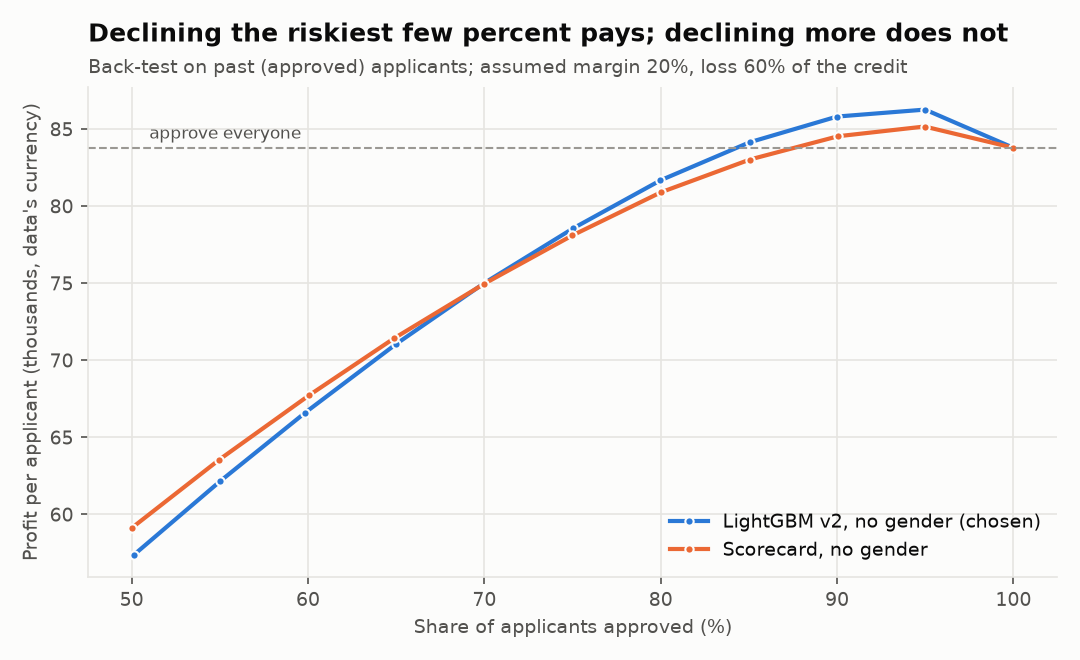

In [12]:
display(pd.read_csv(R / "business_v2" / "policies.csv"))
display(pd.read_csv(R / "business_v2" / "differences.csv"))
sens = pd.read_csv(R / "business_v2" / "sensitivity.csv")
display(sens[sens.model == "lgbm_v2_combo_lr02_x3"])
show(figures.profit_curve(P))

Score bands, KS, the swap-set between LightGBM and the scorecard, and population stability (PSI).

In [13]:
for f in ["score_bands", "ks", "swap_set", "psi"]:
    display(pd.read_csv(R / "credit_v2" / f"{f}.csv"))

,model,band,risk_from_pct,risk_to_pct,applicants,difficulty_rate_pct,cum_approval_pct,cum_difficulty_rate_pct
0,lgbm_v2_combo_lr02_x3,1,0.24,1.50,30752,0.79,10.0,0.79
1,lgbm_v2_combo_lr02_x3,2,1.50,2.13,30751,1.61,20.0,1.20
2,lgbm_v2_combo_lr02_x3,3,2.13,2.80,30751,2.16,30.0,1.52
3,lgbm_v2_combo_lr02_x3,4,2.80,3.60,30751,2.92,40.0,1.87
4,lgbm_v2_combo_lr02_x3,5,3.60,4.63,30751,3.88,50.0,2.27
5,lgbm_v2_combo_lr02_x3,6,4.63,6.04,30751,5.40,60.0,2.80
6,lgbm_v2_combo_lr02_x3,7,6.04,8.14,30751,7.52,70.0,3.47
7,lgbm_v2_combo_lr02_x3,8,8.14,11.63,30751,10.43,80.0,4.34
8,lgbm_v2_combo_lr02_x3,9,11.63,18.84,30751,15.51,90.0,5.58
9,lgbm_v2_combo_lr02_x3,10,18.84,83.92,30751,30.51,100.0,8.07


,model,ks_mean_of_seeds,ks_sd,ks_of_seed_mean_score
0,lgbm_v2_combo_lr02_x3,0.4347,0.0007,0.4367
1,scorecard_full_no_gender,0.3824,0.0007,0.3837


,group,applicants,pct_of_applicants,difficulty_rate_pct
0,approved by both,282609,91.90,5.98
1,approved by LightGBM only,4267,1.39,18.23
2,approved by the scorecard only,10128,3.29,31.08
3,declined by both,10507,3.42,37.97


,what,psi
0,model score,0.0054
1,EXT_SOURCE_3,0.0078
2,EXT_SOURCE_2,0.0151
3,ORGANIZATION_TYPE,0.0055
4,EXT_SOURCE_1,0.0846
5,annuity_to_credit,0.9986
6,term_prev_granted_to_asked,0.0403
7,win_cc_util_3m,0.0102
8,OCCUPATION_TYPE,0.0020
9,bureau_active_debt_to_credit,0.0171


,model,attribute,group,applicants,default_rate_pct,mean_pred_pct,approval_pct,approval_pct_good_payers,default_rate_approved_pct,adverse_impact_ratio
0,lgbm_v2_combo_lr02_x3,gender,F,202448,7.00,7.35,94.98,96.46,5.55,1.000
1,lgbm_v2_combo_lr02_x3,gender,M,105059,10.14,9.47,91.70,94.15,7.75,0.965
2,lgbm_v2_combo_lr02_x3,age band,25-34,72429,10.66,10.72,89.70,92.58,7.79,0.901
3,lgbm_v2_combo_lr02_x3,age band,35-44,84261,8.41,8.20,93.63,95.59,6.49,0.941
4,lgbm_v2_combo_lr02_x3,age band,45-54,70190,7.05,7.13,95.47,96.84,5.72,0.959
5,lgbm_v2_combo_lr02_x3,age band,55-64,60522,5.42,5.48,97.86,98.51,4.80,0.983
6,lgbm_v2_combo_lr02_x3,age band,65+,7876,3.66,3.40,99.54,99.75,3.45,1.000
7,lgbm_v2_combo_lr02_x3,age band,<25,12233,12.29,12.75,87.32,90.21,9.39,0.877
8,lgbm_v2_combo_lr02_x3,family status,Civil marriage,29775,9.94,9.31,91.85,94.39,7.45,0.945
9,lgbm_v2_combo_lr02_x3,family status,Married,196432,7.56,7.88,94.21,95.90,5.90,0.969


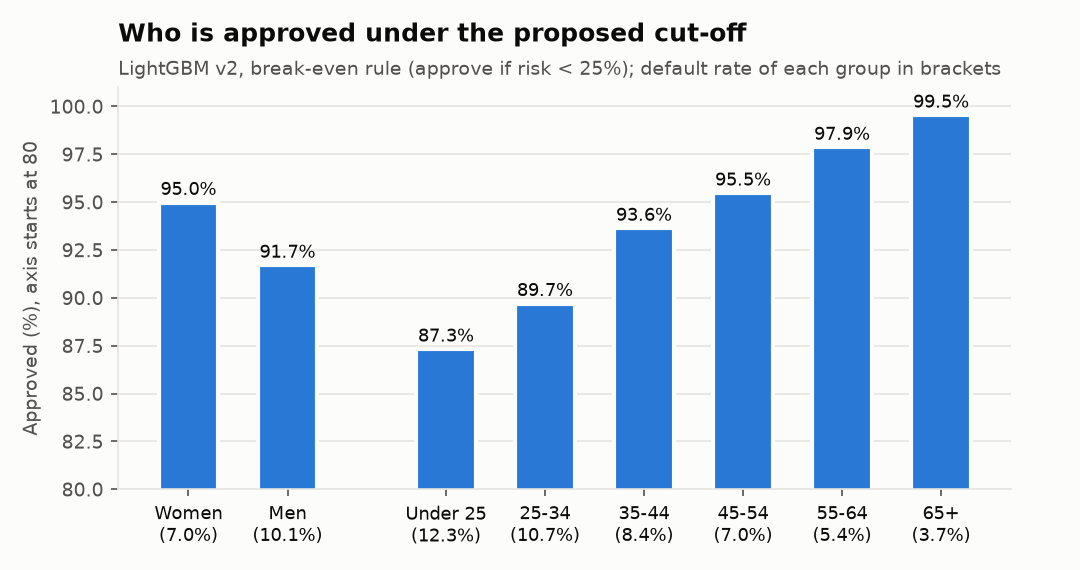

In [14]:
display(pd.read_csv(R / "business_v2" / "policy_groups.csv").query("model == 'lgbm_v2_combo_lr02_x3'"))
show(figures.approval_by_group(P))

## 11. Technical details
- **Code layout:** `homecredit/` holds the shared code (paths, data loading, the one evaluation module
  `evaluate.py`, model code in `models/`, charts in `figures.py`); `eda/`, `pipeline/` (data, feature tables,
  model training, submissions), `experiments/` (noise, paired comparisons, Kaggle check, duplicate check,
  reproducibility) and `analysis/` (calibration, reason codes, error analysis, fairness, proxies, business, credit
  tables, charts). Scripts run as modules from the repository root, e.g. `.venv/bin/python -m pipeline.make_features`.
  `run_all.sh` runs everything in order; `run_v3.sh` holds the v3 work in progress.
- **Chosen model:** LightGBM, 186 columns (v1 plus the `win_`, `stk_` and `term_` groups of
  `pipeline/make_features_v2.py`, without gender, family status and the bureau's monthly history), learning rate
  0.02, early stopping on an inner 10% of each training fold, average of 3 fits (`lgbm_v2_combo_lr02_x3`).
- **Adoption rule:** paired comparison on the same 25 folds (`experiments/compare.py`); gain more than 2 x the
  bootstrap standard error of the gain (seed-0 out-of-fold predictions, 200 resamples) and at least 18 of 25 wins.
  Exploratory one-seed runs compare 5 folds and need 4 of 5 wins; nothing was adopted from them.
- **Calibration:** measured inside each validation fold (section 6). The raw model's average gap is 0.48 points
  against 0.35 from chance alone; cross-fitted isotonic regression brings it to 0.36. A pooled measure across folds
  flatters cross-fitted corrections. Brier score and log loss barely change.
- **Reason codes:** SHAP values of the 3 averaged models are averaged in log-odds, while the prediction averages
  probabilities (a small mismatch). The counterfactual swaps a whole reason group with a random approved applicant's
  values (5 donors), so it tests faithfulness to the model, not real-world causes.
- **Credit tables:** score bands, KS (0.43 for the chosen model vs 0.38 for the scorecard), the swap-set and the
  population stability index are in section 10 (`analysis/credit_tables.py`).
- **For scale (Kaggle leaderboard, not a script):** the competition's winning team scored 0.806 on the private
  leaderboard with, by its public write-up, hundreds to thousands of features and about 90 stacked models.

## 12. Limits
- The target's exact definition (X days late on one of the first Y instalments) is not disclosed.
- Validation uses random folds; there is no time order in the data.
- Only previously approved loans are in the data; the profit numbers are a back-test with assumed margins and losses.
- The fairness cost measured on Kaggle's hidden test (0.003 AUC) is about twice the validation estimate (0.002).
- Possible repeat applicants: grouped folds did not lower the score (section 8).
- A third feature version (v3) with SHAP-based feature reduction is in progress and not part of these results.